# TCC — Análise Comparativa: Local vs Global vs Federado

**Autor:** Násser Assad Ferreira Saleh

## 1. Setup

In [17]:
import sys
from pathlib import Path

PROJETO_DIR = Path.cwd().parent
sys.path.insert(0, str(PROJETO_DIR))

import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from src.task import (
    criar_modelo, preparar_dados, evaluate as avaliar_modelo,
    JANELA, HORIZONTE, COLUNA_ALVO, FEATURES_SELECIONADAS, N_FEATURES,
)
from src.client_app import ARQUIVOS_ESTACOES

plt.rcParams.update({
    "figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 11,
})

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

DADOS_DIR = PROJETO_DIR / "dados"
RESULTS_DIR = PROJETO_DIR / "results"
FEDERADO_DIR = RESULTS_DIR / "Federado"
GLOBAL_DIR = RESULTS_DIR / "Global"
LOCAL_DIR = RESULTS_DIR / "Local"

ARQUIVO_POR_CODIGO = {a.split(" - ")[0]: a for a in ARQUIVOS_ESTACOES}
CODIGOS_ESTACOES = list(ARQUIVO_POR_CODIGO.keys())

In [18]:
print(HORIZONTE)

1


## 2. Funções auxiliares

In [19]:
def carregar_modelo(model_name, state_dict):
    modelo = criar_modelo(model_name, n_features=N_FEATURES)
    modelo.load_state_dict(state_dict, strict=False)
    modelo.to(DEVICE).eval()
    return modelo


def pasta_mais_recente(grupos):
    return {chave: sorted(execucoes)[-1][1] for chave, execucoes in grupos.items()}

## 3. Dados de teste de cada estação

In [20]:
dados_teste = {}
for codigo, nome_arquivo in ARQUIVO_POR_CODIGO.items():
    df = pd.read_csv(DADOS_DIR / nome_arquivo, index_col="timestamp", parse_dates=True)
    _, _, X_test, y_test, escala = preparar_dados(df)
    dados_teste[codigo] = {"X_test": X_test, "y_test": y_test, "escala": escala}

## 4. Avaliação dos checkpoints salvos

In [21]:
grupos = {}
for pasta in FEDERADO_DIR.iterdir():
    if not pasta.is_dir():
        continue
    strategy, model, timestamp = pasta.name.split("_", 2)
    grupos.setdefault((strategy, model), []).append((timestamp, pasta))

linhas, pesos_federado, historicos_federado = [], {}, {}
for (strategy, model), pasta in pasta_mais_recente(grupos).items():
    ck = torch.load(pasta / "checkpoints" / "melhores_pesos.pt", map_location="cpu", weights_only=False)
    # print( ck["model_state_dict"].shape)
    modelo = carregar_modelo(model, ck["model_state_dict"])
    linha = {"Paradigma": "Federado", "Estrategia": strategy.upper(), "Modelo": model.upper(),
             "Rotulo": f"({strategy.upper()} + {model.upper()})"}
    for codigo, dc in dados_teste.items():
        metricas = avaliar_modelo(modelo, dc["X_test"], dc["y_test"], escala=dc["escala"])
        linha[f"RMSE_{codigo}"] = metricas["rmse_celsius"]
        linha[f"MAE_{codigo}"] = metricas["mae_celsius"]
        linha[f"R2_{codigo}"] = metricas["r2"]
    linhas.append(linha)
    pesos_federado[(strategy, model)] = ck["model_state_dict"]
    historicos_federado[(strategy, model)] = json.loads((pasta / "metricas.json").read_text(encoding="utf-8"))["historico"]

df_federado = pd.DataFrame(linhas)
df_federado

,Paradigma,Estrategia,Modelo,Rotulo,RMSE_A701,MAE_A701,R2_A701,RMSE_A706,MAE_A706,R2_A706,RMSE_A744,MAE_A744,R2_A744,RMSE_A755,MAE_A755,R2_A755,RMSE_A771,MAE_A771,R2_A771
0,Federado,FEDAVG,LSTM,(FEDAVG + LSTM),0.808401,0.524833,0.970020,0.918055,0.602057,0.959321,0.794866,0.524388,0.973934,0.843072,0.559301,0.968956,0.778931,0.509778,0.970049
1,Federado,FEDMEDIAN,LSTM,(FEDMEDIAN + LSTM),0.810889,0.525315,0.969836,0.944127,0.622925,0.956977,0.791006,0.520832,0.974186,0.835291,0.548861,0.969527,0.765867,0.494287,0.971045


In [22]:
grupos = {}
for pasta in GLOBAL_DIR.iterdir():
    if not pasta.is_dir():
        continue
    model, timestamp = pasta.name.split("_", 1)
    grupos.setdefault(model, []).append((timestamp, pasta))

linhas, pesos_global, historicos_global = [], {}, {}
for model, pasta in pasta_mais_recente(grupos).items():
    ck = torch.load(pasta / "melhor.pt", map_location="cpu", weights_only=False)
    modelo = carregar_modelo(model, ck["model_state_dict"])
    linha = {"Paradigma": "Global", "Estrategia": "-", "Modelo": model.upper(),
             "Rotulo": f"Global ({model.upper()})"}
    for codigo, dc in dados_teste.items():
        metricas = avaliar_modelo(modelo, dc["X_test"], dc["y_test"], escala=dc["escala"])
        linha[f"RMSE_{codigo}"] = metricas["rmse_celsius"]
        linha[f"MAE_{codigo}"] = metricas["mae_celsius"]
        linha[f"R2_{codigo}"] = metricas["r2"]
    linhas.append(linha)
    pesos_global[model] = ck["model_state_dict"]
    historicos_global[model] = json.loads((pasta / "metricas.json").read_text(encoding="utf-8"))["historico"]

df_global = pd.DataFrame(linhas)
df_global

C:\Users\nasse\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\torch\nn\utils\weight_norm.py:143: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


,Paradigma,Estrategia,Modelo,Rotulo,RMSE_A701,MAE_A701,R2_A701,RMSE_A706,MAE_A706,R2_A706,RMSE_A744,MAE_A744,R2_A744,RMSE_A755,MAE_A755,R2_A755,RMSE_A771,MAE_A771,R2_A771
0,Global,-,LSTM,Global (LSTM),0.816121,0.523032,0.969445,0.901126,0.596519,0.960807,0.811861,0.543427,0.972807,0.844154,0.551238,0.968877,0.758935,0.479511,0.971567
1,Global,-,TCN,Global (TCN),0.818770,0.525719,0.969246,0.904966,0.601485,0.960472,0.805672,0.535680,0.973220,0.857126,0.562428,0.967913,0.769847,0.486014,0.970744


In [23]:
linhas_por_modelo, pesos_local, historicos_local = {}, {}, {}
for estacao_dir in LOCAL_DIR.iterdir():
    if not estacao_dir.is_dir():
        continue
    codigo = estacao_dir.name
    grupos = {}
    for pasta in estacao_dir.iterdir():
        if not pasta.is_dir():
            continue
        model, timestamp = pasta.name.split("_", 1)
        grupos.setdefault(model, []).append((timestamp, pasta))

    for model, pasta in pasta_mais_recente(grupos).items():
        ck = torch.load(pasta / "melhor.pt", map_location="cpu", weights_only=False)
        modelo = carregar_modelo(model, ck["model_state_dict"])
        dc = dados_teste[codigo]
        metricas = avaliar_modelo(modelo, dc["X_test"], dc["y_test"], escala=dc["escala"])
        linha = linhas_por_modelo.setdefault(model, {
            "Paradigma": "Local", "Estrategia": "-", "Modelo": model.upper(), "Rotulo": f"Local ({model.upper()})",
        })
        linha[f"RMSE_{codigo}"] = metricas["rmse_celsius"]
        linha[f"MAE_{codigo}"] = metricas["mae_celsius"]
        linha[f"R2_{codigo}"] = metricas["r2"]
        pesos_local[(codigo, model)] = ck["model_state_dict"]
        historicos_local[(codigo, model)] = json.loads((pasta / "metricas.json").read_text(encoding="utf-8"))["historico"]

df_local = pd.DataFrame(list(linhas_por_modelo.values()))
df_local

C:\Users\nasse\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\torch\nn\utils\weight_norm.py:143: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
C:\Users\nasse\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\torch\nn\utils\weight_norm.py:143: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
C:\Users\nasse\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\torch\nn\utils\weight_norm.py:143: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
C:\Users\nass

,Paradigma,Estrategia,Modelo,Rotulo,RMSE_A701,MAE_A701,R2_A701,RMSE_A706,MAE_A706,R2_A706,RMSE_A744,MAE_A744,R2_A744,RMSE_A755,MAE_A755,R2_A755,RMSE_A771,MAE_A771,R2_A771
0,Local,-,LSTM,Local (LSTM),0.826959,0.537331,0.968628,0.887997,0.604942,0.961941,0.833016,0.556095,0.971372,1.032296,0.706236,0.953457,1.417865,1.047720,0.900761
1,Local,-,TCN,Local (TCN),0.835750,0.550403,0.967958,0.898792,0.610358,0.961010,0.856155,0.585150,0.969759,1.031060,0.726836,0.953569,1.588161,1.173764,0.875491


## 5. Tabela comparativa final

In [24]:
df_final = pd.concat([df_federado, df_global, df_local], ignore_index=True)
colunas_mae = [f"MAE_{codigo}" for codigo in CODIGOS_ESTACOES]
colunas_rmse = [f"RMSE_{codigo}" for codigo in CODIGOS_ESTACOES]
colunas_r2 = [f"R2_{codigo}" for codigo in CODIGOS_ESTACOES]

df_final["Media_RMSE"] = df_final[colunas_rmse].mean(axis=1)
df_final["Media_MAE"] = df_final[colunas_mae].mean(axis=1)
df_final["Media_R2"] = df_final[colunas_r2].mean(axis=1)
df_final = df_final.sort_values(["Paradigma", "Modelo", "Estrategia"]).set_index("Rotulo")

tabela_rmse = df_final[colunas_rmse + ["Media_RMSE"]].round(3)
tabela_mae = df_final[colunas_mae + ["Media_MAE"]].round(3)
tabela_r2 = df_final[colunas_r2 + ["Media_R2"]].round(3)

display(tabela_rmse.style.background_gradient(cmap="RdYlGn_r", axis=0).format("{:.4f}"))
display(tabela_mae.style.background_gradient(cmap="RdYlGn_r", axis=0).format("{:.4f}"))
display(tabela_r2.style.background_gradient(cmap="RdYlGn", axis=0).format("{:.4f}"))

,RMSE_A701,RMSE_A706,RMSE_A744,RMSE_A755,RMSE_A771,Media_RMSE
Rotulo,,,,,,
(FEDAVG + LSTM),0.8080,0.9180,0.7950,0.8430,0.7790,0.8290
(FEDMEDIAN + LSTM),0.8110,0.9440,0.7910,0.8350,0.7660,0.8290
Global (LSTM),0.8160,0.9010,0.8120,0.8440,0.7590,0.8260
Global (TCN),0.8190,0.9050,0.8060,0.8570,0.7700,0.8310
Local (LSTM),0.8270,0.8880,0.8330,1.0320,1.4180,1.0000
Local (TCN),0.8360,0.8990,0.8560,1.0310,1.5880,1.0420


,MAE_A701,MAE_A706,MAE_A744,MAE_A755,MAE_A771,Media_MAE
Rotulo,,,,,,
(FEDAVG + LSTM),0.5250,0.6020,0.5240,0.5590,0.5100,0.5440
(FEDMEDIAN + LSTM),0.5250,0.6230,0.5210,0.5490,0.4940,0.5420
Global (LSTM),0.5230,0.5970,0.5430,0.5510,0.4800,0.5390
Global (TCN),0.5260,0.6010,0.5360,0.5620,0.4860,0.5420
Local (LSTM),0.5370,0.6050,0.5560,0.7060,1.0480,0.6900
Local (TCN),0.5500,0.6100,0.5850,0.7270,1.1740,0.7290


,R2_A701,R2_A706,R2_A744,R2_A755,R2_A771,Media_R2
Rotulo,,,,,,
(FEDAVG + LSTM),0.9700,0.9590,0.9740,0.9690,0.9700,0.9680
(FEDMEDIAN + LSTM),0.9700,0.9570,0.9740,0.9700,0.9710,0.9680
Global (LSTM),0.9690,0.9610,0.9730,0.9690,0.9720,0.9690
Global (TCN),0.9690,0.9600,0.9730,0.9680,0.9710,0.9680
Local (LSTM),0.9690,0.9620,0.9710,0.9530,0.9010,0.9510
Local (TCN),0.9680,0.9610,0.9700,0.9540,0.8750,0.9460


## 6. Gráfico comparativo — RMSE por combinação e estação

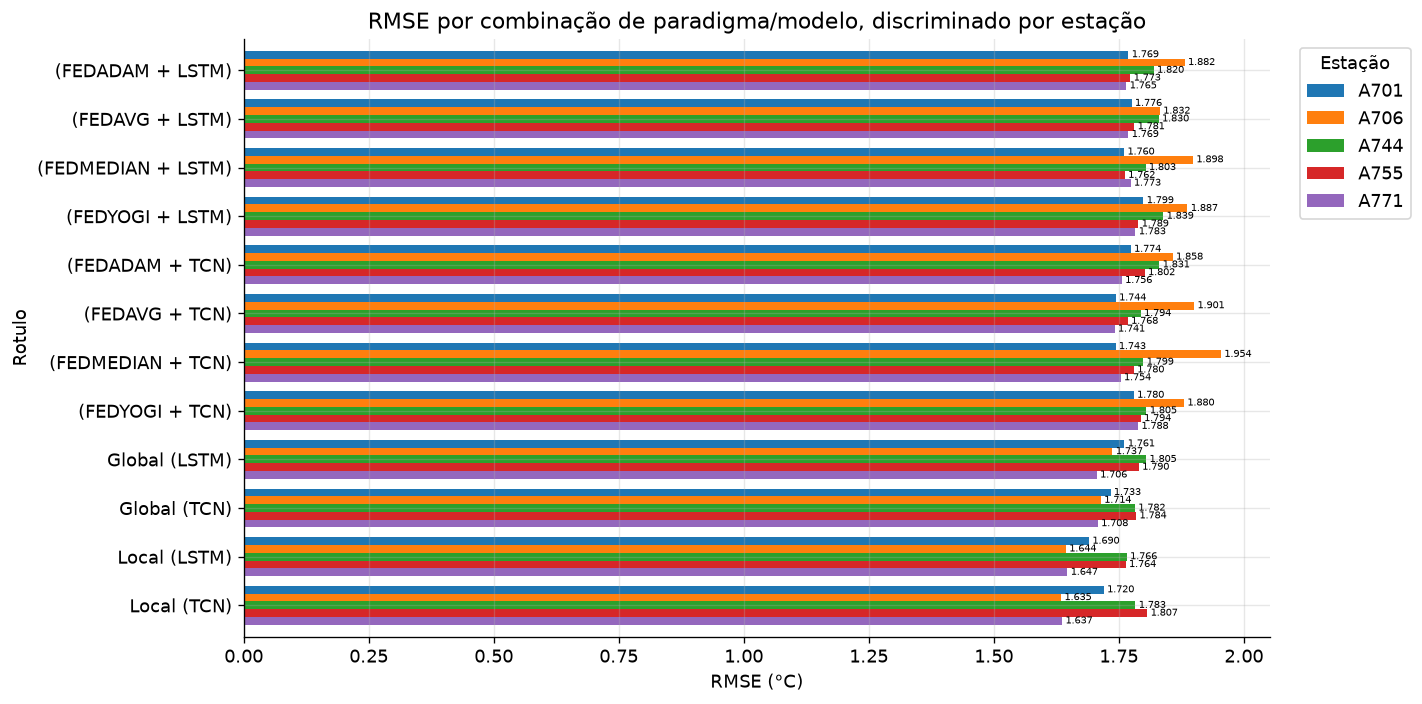

In [9]:
fig, ax = plt.subplots(figsize=(12, max(4, 0.5 * len(tabela_rmse))))
tabela_rmse[CODIGOS_ESTACOES].plot(kind="barh", ax=ax, width=0.8)
ax.set_xlabel("RMSE (°C)")
ax.set_title("RMSE por combinação de paradigma/modelo, discriminado por estação")
ax.legend(title="Estação", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.invert_yaxis()
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=6, padding=2)
plt.tight_layout()
plt.show()

## 7. Convergência das rodadas federadas

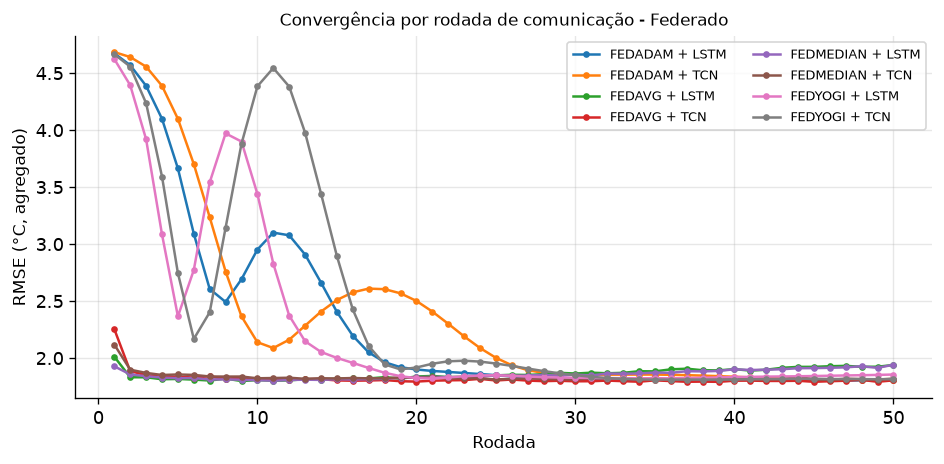

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
cores = plt.cm.tab10.colors
for i, ((strategy, model), historico) in enumerate(historicos_federado.items()):
    rodadas = [h["rodada"] for h in historico]
    rmse = [h["rmse_global"] for h in historico]
    ax.plot(rodadas, rmse, marker="o", markersize=3, lw=1.5, color=cores[i % len(cores)],
            label=f"{strategy.upper()} + {model.upper()}")
ax.set_xlabel("Rodada", fontsize=10)
ax.set_ylabel("RMSE (°C, agregado)", fontsize=10)
ax.set_title("Convergência por rodada de comunicação - Federado", fontsize=10)
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

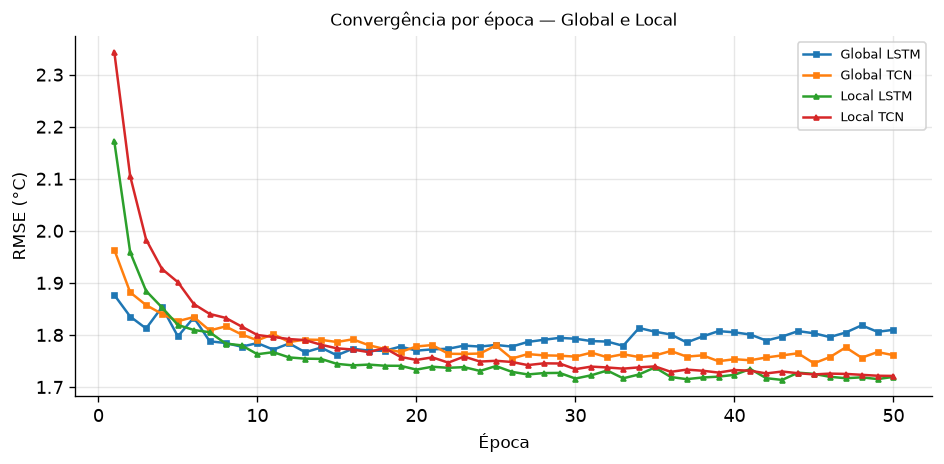

In [11]:
desvio_medio = np.mean([dc["escala"][1] for dc in dados_teste.values()])

fig, ax = plt.subplots(figsize=(8, 4))
cores = plt.cm.tab10.colors
i = 0

for model, historico in historicos_global.items():
    epocas = [h["epoca"] for h in historico]
    rmse = [h["rmse_celsius"] * desvio_medio for h in historico]
    ax.plot(epocas, rmse, marker="s", markersize=3, lw=1.5, color=cores[i % len(cores)],
            label=f"Global {model.upper()}")
    i += 1

for model in ("lstm", "tcn"):
    historicos_modelo = [h for (codigo, m), h in historicos_local.items() if m == model]
    epocas = [h["epoca"] for h in historicos_modelo[0]]
    rmse = [np.mean([hist[e]["rmse_celsius"] for hist in historicos_modelo]) for e in range(len(epocas))]
    ax.plot(epocas, rmse, marker="^", markersize=3, lw=1.5, color=cores[i % len(cores)],
            label=f"Local {model.upper()}")
    i += 1

ax.set_xlabel("Época", fontsize=10)
ax.set_ylabel("RMSE (°C)", fontsize=10)
ax.set_title("Convergência por época — Global e Local", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 8. Real vs Predito — uma semana específica

In [12]:
ESTACAO_PLOT = "A701"
N_HORAS_SEMANA = 168
INICIO_SEMANA = 500

nome_arquivo = ARQUIVO_POR_CODIGO[ESTACAO_PLOT]
df = pd.read_csv(DADOS_DIR / nome_arquivo, index_col="timestamp", parse_dates=True)
n_janelas = len(df) - JANELA - HORIZONTE + 1
n_treino = int(n_janelas * 0.8)
timestamps_teste = df.index[np.arange(n_treino, n_janelas) + JANELA + HORIZONTE - 1]
fim_semana = INICIO_SEMANA + N_HORAS_SEMANA
horas_semana = timestamps_teste[INICIO_SEMANA:fim_semana]

C:\Users\nasse\AppData\Local\Temp\ipykernel_9768\2787040080.py:27: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


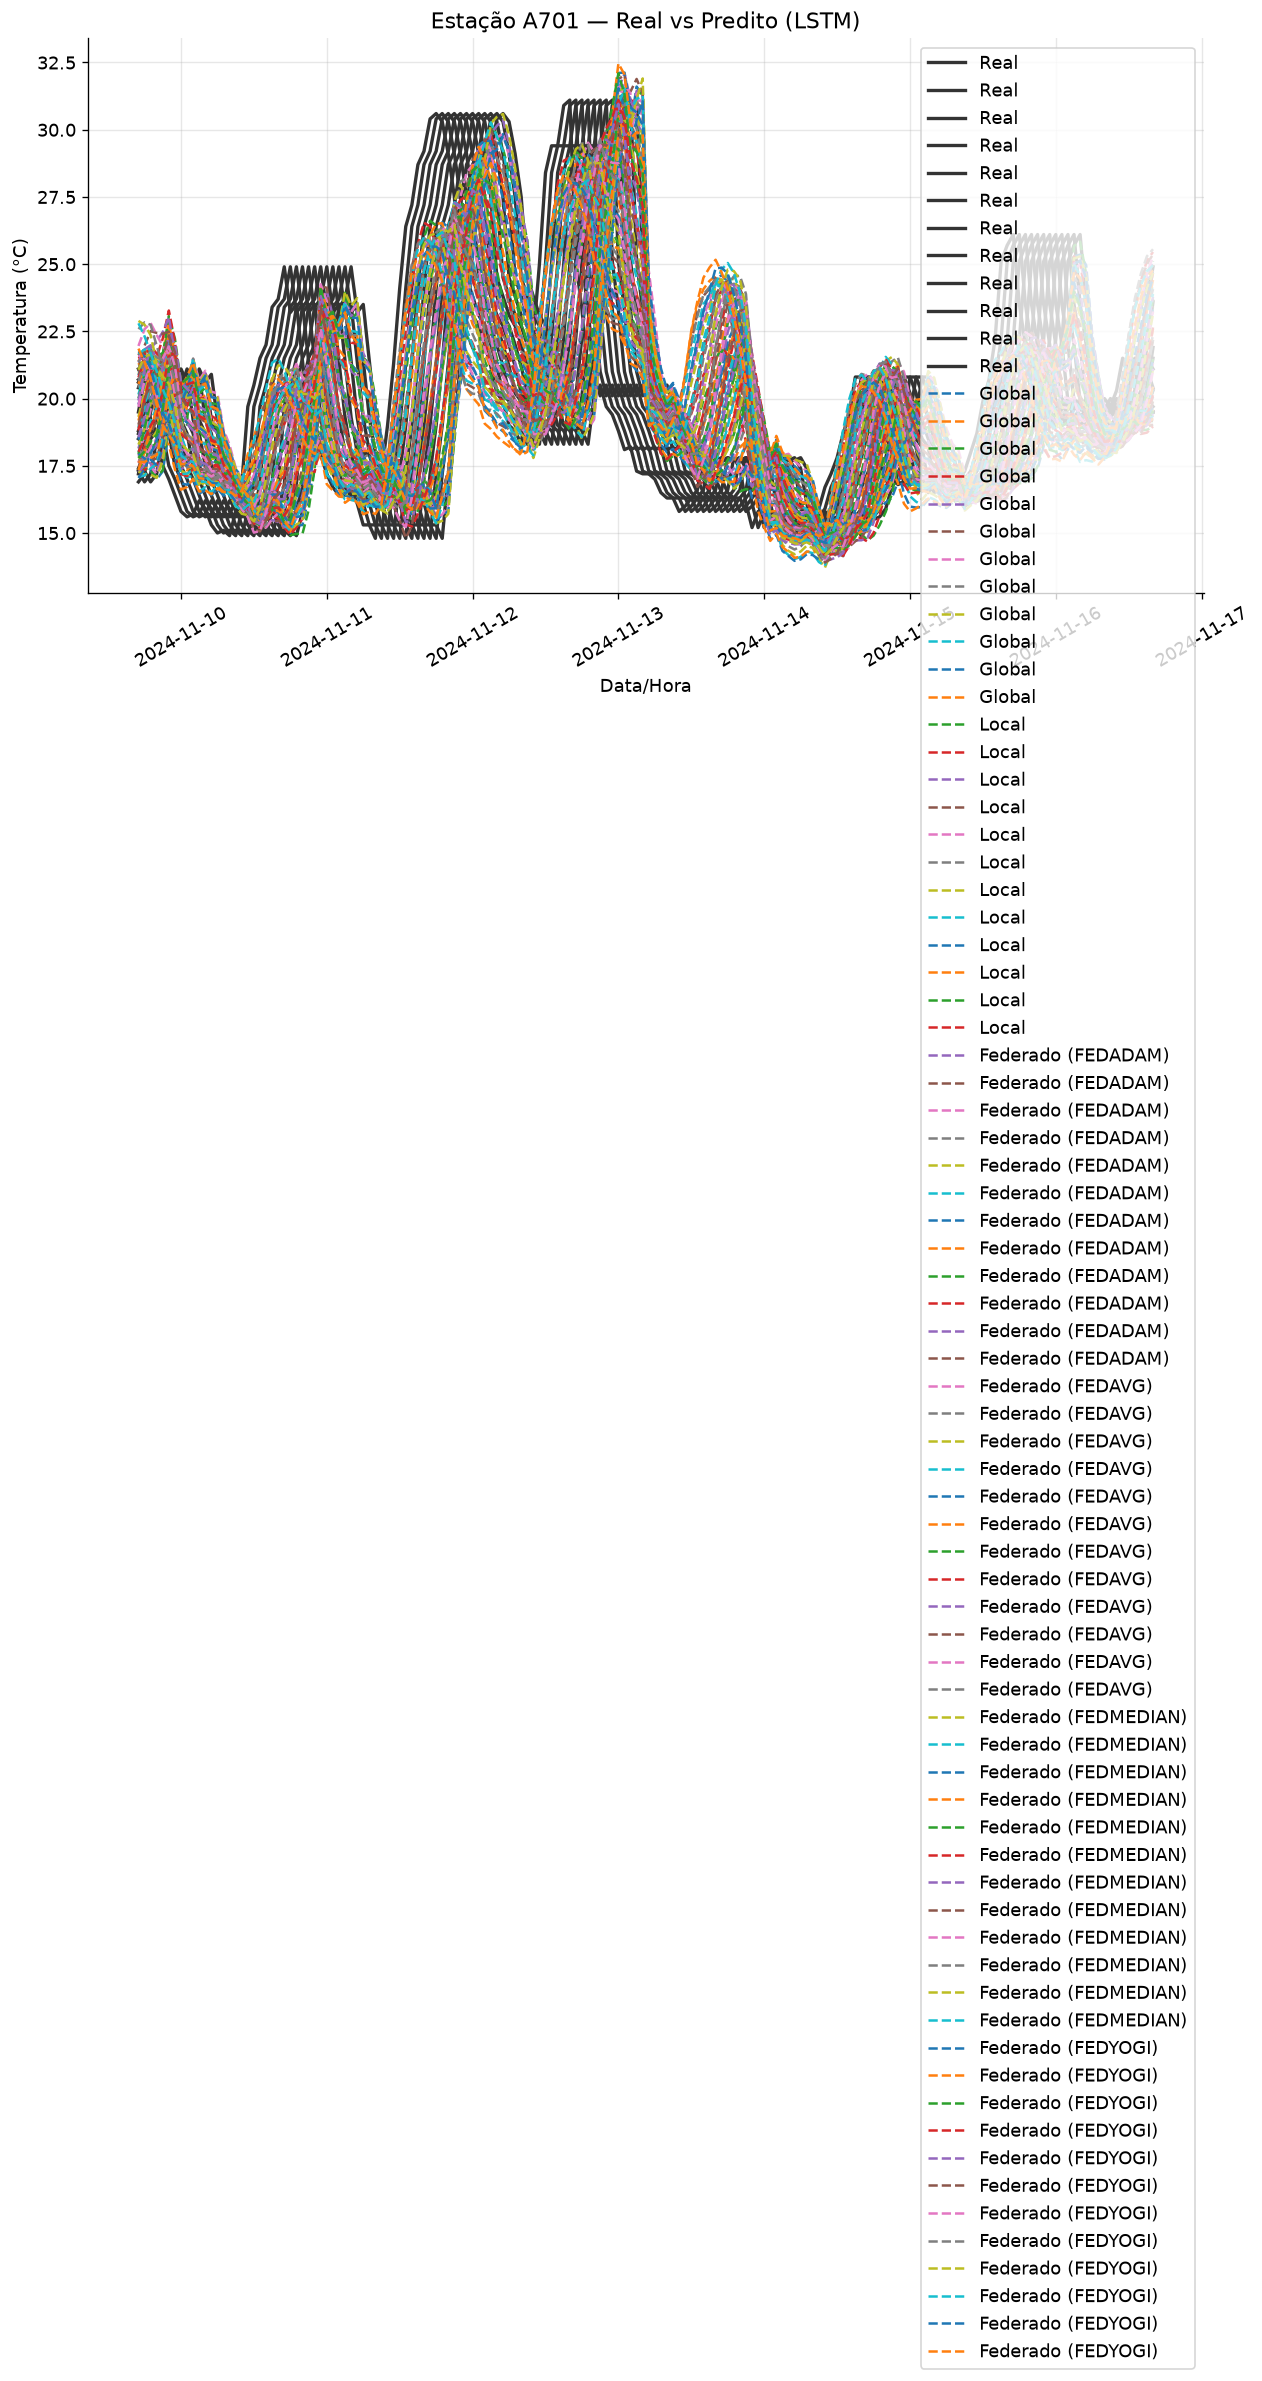

C:\Users\nasse\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\torch\nn\utils\weight_norm.py:143: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


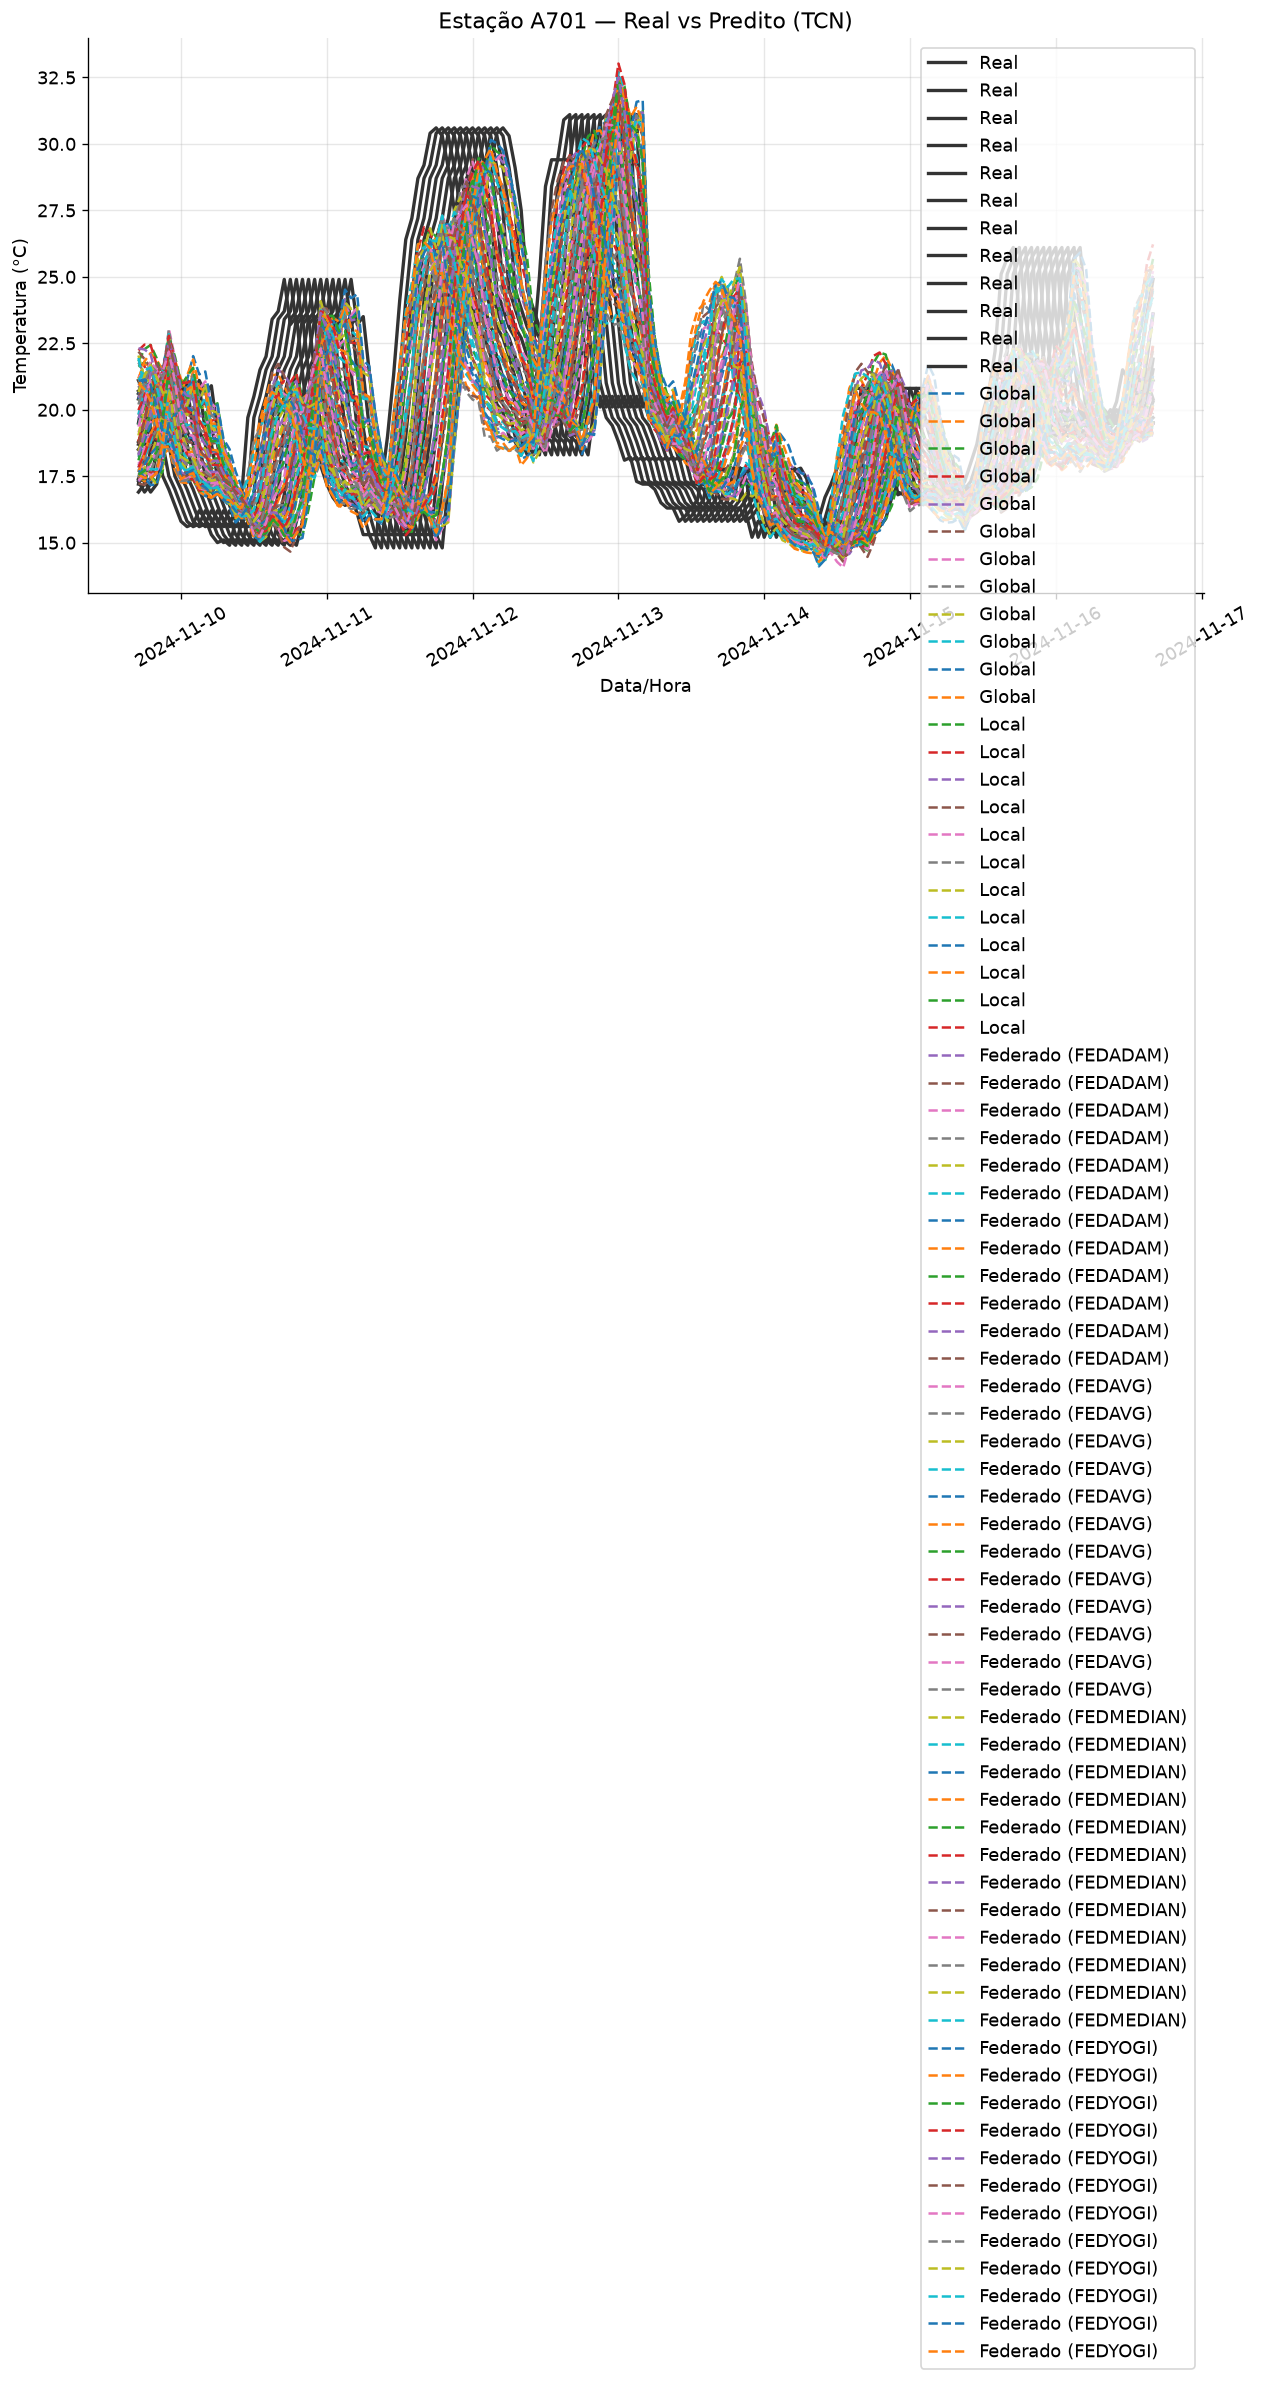

In [13]:
def plotar_semana(model_name):
    dc = dados_teste[ESTACAO_PLOT]
    t_media, t_desvio = dc["escala"]
    X_semana = dc["X_test"][INICIO_SEMANA:fim_semana]
    y_real_c = (dc["y_test"][INICIO_SEMANA:fim_semana].numpy() * t_desvio) + t_media

    fig, ax = plt.subplots(figsize=(12, 6))
    ax.plot(horas_semana, y_real_c, color="#333333", lw=2, label="Real")

    def prever(state_dict):
        modelo = carregar_modelo(model_name, state_dict)
        with torch.no_grad():
            pred = modelo(X_semana.to(DEVICE)).cpu().numpy().squeeze()
        return (pred * t_desvio) + t_media

    ax.plot(horas_semana, prever(pesos_global[model_name]), "--", lw=1.5, label="Global")
    ax.plot(horas_semana, prever(pesos_local[(ESTACAO_PLOT, model_name)]), "--", lw=1.5, label="Local")
    for (estrategia, m), sd in pesos_federado.items():
        if m == model_name:
            ax.plot(horas_semana, prever(sd), "--", lw=1.5, label=f"Federado ({estrategia.upper()})")

    ax.set_title(f"Estação {ESTACAO_PLOT} — Real vs Predito ({model_name.upper()})")
    ax.set_ylabel("Temperatura (°C)")
    ax.set_xlabel("Data/Hora")
    ax.legend()
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()


plotar_semana("lstm")
plotar_semana("tcn")

### Plot das 12h após 24h

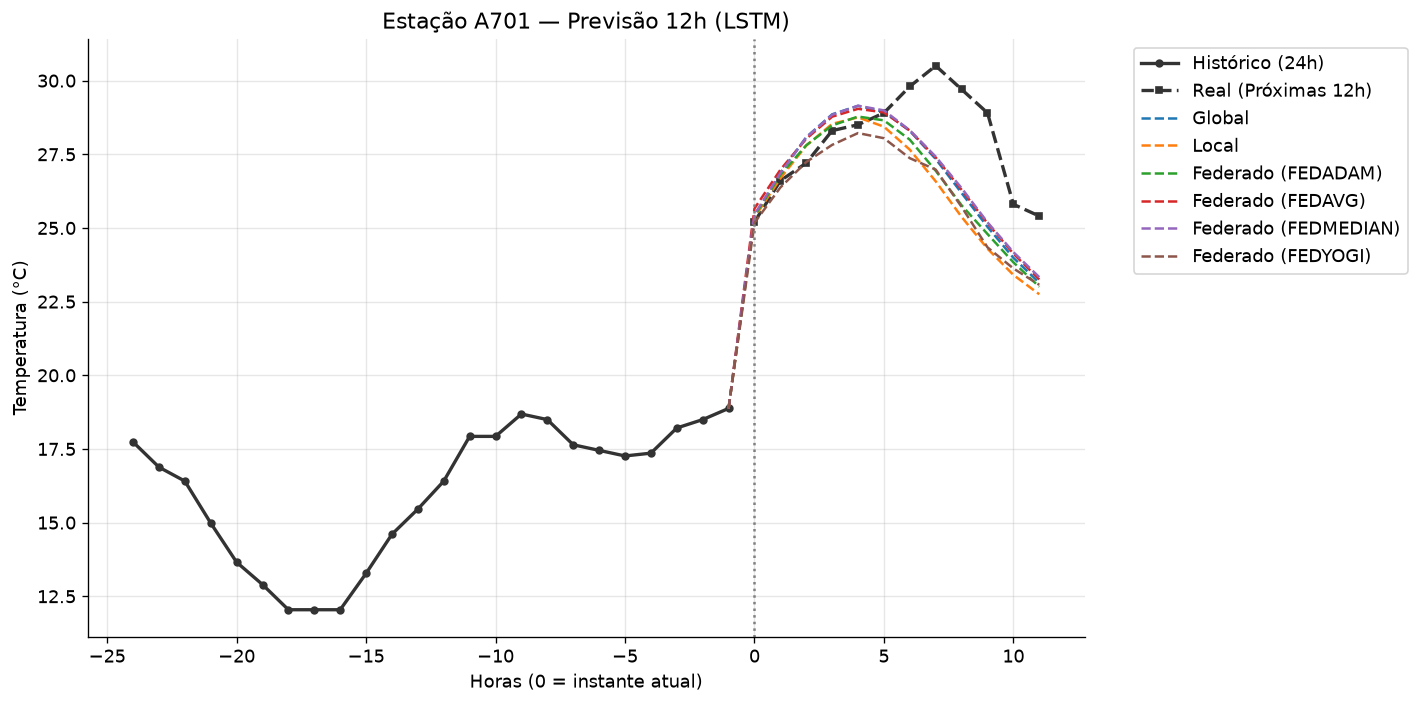

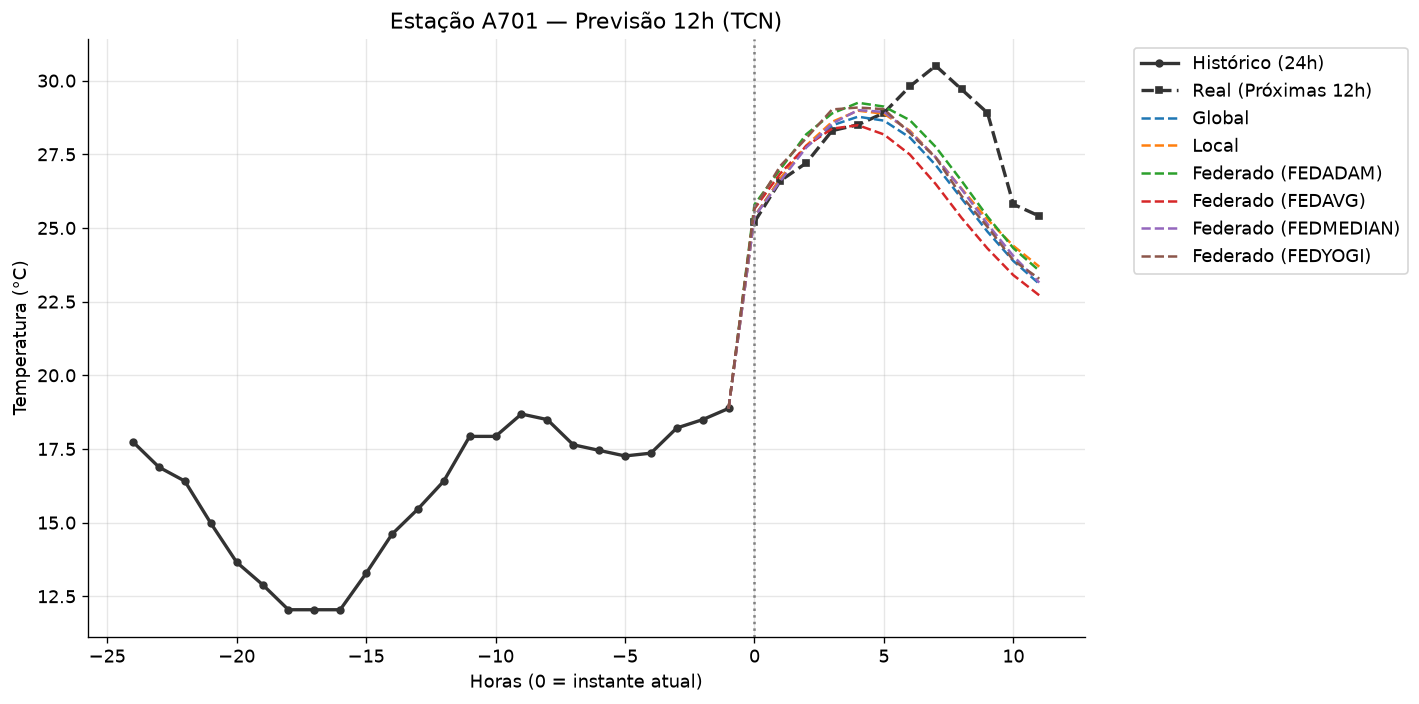

In [18]:
import matplotlib.pyplot as plt
import numpy as np
import torch

def plotar_janela_futura(estacao, model_name, amostra_idx=-1):
    # 1. Extrai o dicionário da estação e sua escala específica
    dc = dados_teste[estacao]
    t_media, t_desvio = dc["escala"]
    
   # 2. Isola a amostra mantendo a dimensão do batch (1, JANELA, FEATURES)
    X_amostra = dc["X_test"][amostra_idx].unsqueeze(0)
    
    # Extrai e desnormaliza o Y correspondente
    y_real = dc["y_test"][amostra_idx].cpu().numpy().squeeze()
    y_real_c = (y_real * t_desvio) + t_media
    
    # Histórico das últimas 24h (assumindo temperatura como última feature [-1])
    historico_24h = X_amostra[0, :, -1].cpu().numpy().squeeze()
    historico_24h_c = (historico_24h * t_desvio) + t_media
    
    # Eixos X (-24 a -1 para o passado, 0 a 11 para o futuro)
    eixo_x_passado = np.arange(-JANELA, 0)
    eixo_x_futuro = np.arange(0, HORIZONTE)
    
    # Inicializa o plot
    fig, ax = plt.subplots(figsize=(12, 6))
    
    # Plota o passado e o alvo real
    ax.plot(eixo_x_passado, historico_24h_c, color="#333333", lw=2, marker='o', ms=4, label="Histórico (24h)")
    ax.plot(eixo_x_futuro, y_real_c, color="#333333", ls="--", lw=2, marker='s', ms=4, label="Real (Próximas 12h)")
    
    # 3. Função interna de previsão (exatamente como no seu exemplo)
    def prever(state_dict):
        modelo = carregar_modelo(model_name, state_dict)
        with torch.no_grad():
            pred = modelo(X_amostra.to(DEVICE)).cpu().numpy().squeeze()
        return (pred * t_desvio) + t_media
    
    # Função auxiliar apenas para conectar a linha da previsão ao último ponto do histórico
    def plotar_linha_pred(y_pred, rotulo):
        eixo_x_conectado = np.concatenate(([-1], eixo_x_futuro))
        y_pred_conectado = np.concatenate(([historico_24h_c[-1]], y_pred))
        ax.plot(eixo_x_conectado, y_pred_conectado, "--", lw=1.5, label=rotulo)

    # 4. Gera as previsões usando a função interna
    plotar_linha_pred(prever(pesos_global[model_name]), "Global")
    plotar_linha_pred(prever(pesos_local[(estacao, model_name)]), "Local")
    
    for (estrategia, m), sd in pesos_federado.items():
        if m == model_name:
            plotar_linha_pred(prever(sd), f"Federado ({estrategia.upper()})")

    # Estética do gráfico
    ax.set_title(f"Estação {estacao} — Previsão 12h ({model_name.upper()})")
    ax.set_ylabel("Temperatura (°C)")
    ax.set_xlabel("Horas (0 = instante atual)")
    ax.axvline(x=0, color='gray', linestyle=':', lw=1.5)
    
    # Legenda fora do gráfico para não cobrir as linhas
    ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Para chamar, basta passar a estação e a arquitetura desejada:
plotar_janela_futura('A701', 'lstm')
plotar_janela_futura('A701', 'tcn')

## 9. Análise Out-of-Time (OOT)

In [34]:
def preparar_oot(codigo, caminho_oot):
    nome_arquivo = ARQUIVO_POR_CODIGO[codigo]
    df_hist = pd.read_csv(DADOS_DIR / nome_arquivo, index_col="timestamp", parse_dates=True)
    df_oot = pd.read_csv(caminho_oot, index_col="timestamp", parse_dates=True)
    df_concat = pd.concat([df_hist, df_oot]).sort_index()
    H, O = len(df_hist), len(df_oot)
    n_total = H + O - JANELA - HORIZONTE + 1
    split = (H - JANELA - HORIZONTE + 1) / n_total
    _, _, X_oot, y_oot, escala_oot = preparar_dados(df_concat, split=split)
    return X_oot, y_oot, escala_oot

In [ ]:
OOT_DIR = DADOS_DIR / "oot"

dados_oot = {}
for codigo, nome_arquivo in ARQUIVO_POR_CODIGO.items():
    print("Preparando para OOT:", codigo," - ", nome_arquivo)
    caminho = OOT_DIR / nome_arquivo.replace(".csv", " - OOT.csv")
    if not caminho.exists():
        continue
    X_oot, y_oot, escala_oot = preparar_oot(codigo, caminho)
    dados_oot[codigo] = {"X_test": X_oot, "y_test": y_oot, "escala": escala_oot}

In [36]:
linhas_rmse, linhas_mae = [], []

for (strategy, model), sd in pesos_federado.items():
    modelo = carregar_modelo(model, sd)
    linha_r = {"Paradigma": "Federado", "Estrategia": strategy.upper(), "Modelo": model.upper(),
               "Rotulo": f"({strategy.upper()} + {model.upper()})"}
    linha_m = dict(linha_r)
    for codigo, dc in dados_oot.items():
        metricas = avaliar_modelo(modelo, dc["X_test"], dc["y_test"], escala=dc["escala"])
        linha_r[codigo] = metricas["rmse_celsius"]
        linha_m[codigo] = metricas["mae_celsius"]
    linhas_rmse.append(linha_r)
    linhas_mae.append(linha_m)

for model, sd in pesos_global.items():
    modelo = carregar_modelo(model, sd)
    linha_r = {"Paradigma": "Global", "Estrategia": "-", "Modelo": model.upper(), "Rotulo": f"Global ({model.upper()})"}
    linha_m = dict(linha_r)
    for codigo, dc in dados_oot.items():
        metricas = avaliar_modelo(modelo, dc["X_test"], dc["y_test"], escala=dc["escala"])
        linha_r[codigo] = metricas["rmse_celsius"]
        linha_m[codigo] = metricas["mae_celsius"]
    linhas_rmse.append(linha_r)
    linhas_mae.append(linha_m)

for model in ("lstm", "tcn"):
    linha_r = {"Paradigma": "Local", "Estrategia": "-", "Modelo": model.upper(), "Rotulo": f"Local ({model.upper()})"}
    linha_m = dict(linha_r)
    for codigo in dados_oot:
        modelo = carregar_modelo(model, pesos_local[(codigo, model)])
        dc = dados_oot[codigo]
        metricas = avaliar_modelo(modelo, dc["X_test"], dc["y_test"], escala=dc["escala"])
        linha_r[codigo] = metricas["rmse_celsius"]
        linha_m[codigo] = metricas["mae_celsius"]
    linhas_rmse.append(linha_r)
    linhas_mae.append(linha_m)

tabela_oot_rmse = pd.DataFrame(linhas_rmse).set_index("Rotulo")
tabela_oot_mae = pd.DataFrame(linhas_mae).set_index("Rotulo")
colunas_oot = [c for c in CODIGOS_ESTACOES if c in tabela_oot_rmse.columns]
tabela_oot_rmse["Media"] = tabela_oot_rmse[colunas_oot].mean(axis=1)
tabela_oot_mae["Media"] = tabela_oot_mae[colunas_oot].mean(axis=1)

display(tabela_oot_rmse[colunas_oot + ["Media"]].round(4).style.background_gradient(cmap="RdYlGn_r", axis=0).format("{:.4f}"))
display(tabela_oot_mae[colunas_oot + ["Media"]].round(4).style.background_gradient(cmap="RdYlGn_r", axis=0).format("{:.4f}"))

C:\Users\nasse\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\torch\nn\utils\weight_norm.py:143: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
C:\Users\nasse\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\pandas\io\formats\style.py:4202: RuntimeWarning: All-NaN slice encountered
  smin = np.nanmin(gmap) if vmin is None else vmin
C:\Users\nasse\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\pandas\io\formats\style.py:4203: RuntimeWarning: All-NaN slice encountered
  smax = np.nanmax(gmap) if vmax is None else vmax


,A701,A771,Media
Rotulo,,,
(FEDADAM + LSTM),nan,0.7840,0.7840
(FEDADAM + TCN),nan,0.8135,0.8135
(FEDAVG + LSTM),nan,0.7783,0.7783
(FEDAVG + TCN),nan,0.7896,0.7896
(FEDMEDIAN + LSTM),nan,0.7750,0.7750
(FEDMEDIAN + TCN),nan,0.7894,0.7894
(FEDYOGI + LSTM),nan,0.7793,0.7793
(FEDYOGI + TCN),nan,0.8030,0.8030
Global (LSTM),nan,0.7753,0.7753


,A701,A771,Media
Rotulo,,,
(FEDADAM + LSTM),nan,0.4938,0.4938
(FEDADAM + TCN),nan,0.5145,0.5145
(FEDAVG + LSTM),nan,0.4836,0.4836
(FEDAVG + TCN),nan,0.4911,0.4911
(FEDMEDIAN + LSTM),nan,0.4850,0.4850
(FEDMEDIAN + TCN),nan,0.4918,0.4918
(FEDYOGI + LSTM),nan,0.4865,0.4865
(FEDYOGI + TCN),nan,0.5130,0.5130
Global (LSTM),nan,0.4814,0.4814


## 10. Resumo final para o TCC

In [38]:
for rotulo, linha in df_final.iterrows():
    print(f"{linha['Paradigma']:<10}: {rotulo:<40} | Media RMSE = {linha['Media']:.4f}C")

melhor = df_final["Media"].idxmin()
print(f"\nMelhor combinacao geral: {melhor} (Media RMSE = {df_final.loc[melhor, 'Media']:.4f}C)")

Federado  : (FEDADAM + LSTM)                         | Media RMSE = 0.8307C
Federado  : (FEDAVG + LSTM)                          | Media RMSE = 0.8221C
Federado  : (FEDMEDIAN + LSTM)                       | Media RMSE = 0.8223C
Federado  : (FEDYOGI + LSTM)                         | Media RMSE = 0.8211C
Federado  : (FEDADAM + TCN)                          | Media RMSE = 0.8562C
Federado  : (FEDAVG + TCN)                           | Media RMSE = 0.8285C
Federado  : (FEDMEDIAN + TCN)                        | Media RMSE = 0.8310C
Federado  : (FEDYOGI + TCN)                          | Media RMSE = 0.8414C
Global    : Global (LSTM)                            | Media RMSE = 0.8130C
Global    : Global (TCN)                             | Media RMSE = 0.8178C
Local     : Local (LSTM)                             | Media RMSE = 0.8075C
Local     : Local (TCN)                              | Media RMSE = 0.8133C

Melhor combinacao geral: Local (LSTM) (Media RMSE = 0.8075C)
